# Manuscript Figures (Figures 1–7)

This notebook renders all seven figures of the paper from the saved outputs under `outputs/` and saves both vector PDF and 300-dpi PNG copies to `figures/`.

Run the analysis scripts (`scripts/01_build_networks.py` through `scripts/04_task_phases.py`) first to populate `outputs/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse, FancyArrowPatch, Patch, Polygon, Rectangle
from matplotlib.ticker import MaxNLocator
from matplotlib.transforms import blended_transform_factory
from scipy.ndimage import gaussian_filter1d

REPO = Path.cwd().resolve()
if REPO.name == "notebooks":
    REPO = REPO.parent

OUT = REPO / "outputs"
PART1 = OUT / "part1"
PART2 = OUT / "part2"
PART3 = OUT / "part3"
FIG_DIR = REPO / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Shared palette and typography
PMD = "#4477AA"
M1 = "#CC6677"
AREA_COLORS = {"PMd": PMD, "M1": M1}
PRIMARY = "#238A8D"
AUXILIARY = "#8266A8"
REFERENCE = "#9BADBC"
INK = "#111111"
GRAY = "#666666"
LIGHT = "#DDDDDD"

PHASES = ("baseline", "delay", "reaction", "movement")
PHASE_LABELS = {"baseline": "Baseline", "delay": "Delay", "reaction": "Reaction", "movement": "Movement"}
PHASE_COLORS = {"baseline": "#E3B23C", "delay": "#D9822B", "reaction": "#B5541C", "movement": "#6B3410"}

AREA_CMAP = ListedColormap([PMD, M1])
CORRELATION_CMAP = plt.get_cmap("RdBu_r").copy()
CORRELATION_CMAP.set_bad("#E5E5E5")
WEIGHT_CMAP = LinearSegmentedColormap.from_list("positive_r", CORRELATION_CMAP(np.linspace(0.5, 1.0, 128)))

DOUBLE = 7.0  # PNAS double-column width (inches)


def apply_style():
    plt.rcParams.update({
        "font.family": "DejaVu Sans", "font.size": 8,
        "axes.titlesize": 8, "axes.labelsize": 8,
        "xtick.labelsize": 7, "ytick.labelsize": 7,
        "legend.fontsize": 7, "axes.spines.top": False,
        "axes.spines.right": False, "axes.linewidth": 0.6,
        "axes.edgecolor": INK, "axes.axisbelow": True,
        "xtick.major.width": 0.6, "ytick.major.width": 0.6,
        "xtick.major.size": 3, "ytick.major.size": 3,
        "text.color": INK, "axes.labelcolor": INK,
        "xtick.color": INK, "ytick.color": INK,
        "savefig.facecolor": "white", "figure.facecolor": "white",
        "mathtext.fontset": "dejavusans", "axes.unicode_minus": True,
        "pdf.fonttype": 42, "ps.fonttype": 42,
        "axes.titlepad": 9, "legend.frameon": False,
    })


def panel_label(fig, x: float, y: float, letter: str, title: str = ""):
    fig.text(x, y, letter, fontsize=10, fontweight="bold", color=INK, va="top")
    if title:
        fig.text(x + 0.028, y - 0.002, title, fontsize=8.5, va="top")


def save_fig(fig, stem: str):
    fig.savefig(FIG_DIR / f"{stem}.pdf")
    fig.savefig(FIG_DIR / f"{stem}.png", dpi=300)
    plt.show()


apply_style()
print("Outputs directory:", OUT)
print("Figures directory:", FIG_DIR)

Outputs directory: /home/yangxi/workspace/be5660/motor_cortex_networks/outputs
Figures directory: /home/yangxi/workspace/be5660/motor_cortex_networks/figures


## Figure 1: Methods schematic

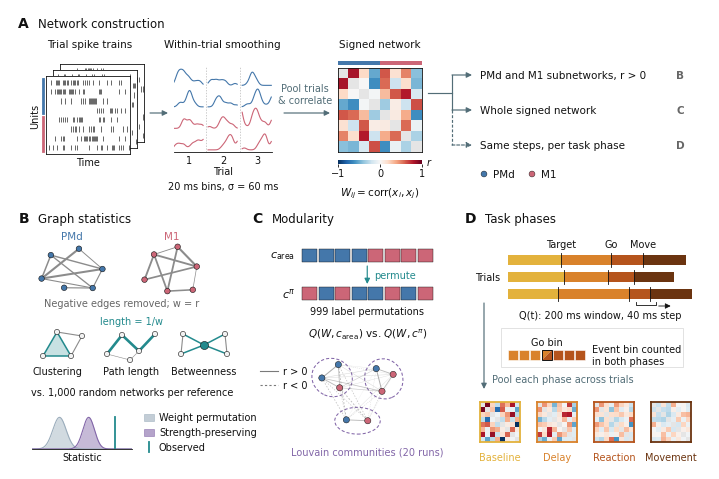

In [2]:
W_IN, H_IN = DOUBLE, 4.6
FLOW = "#526D77"
NODE = "#F2F2F2"

# Analysis parameters printed on the schematic
S = dict(bin_ms=20, sigma_ms=60, n_null=1000, n_perm=999, n_runs=20, win_ms=200, step_ms=40)

# Synthetic 8-unit, 3-trial example for panel A & C
rng = np.random.default_rng(41)
groups = np.array([0, 0, 1, 2, 0, 1, 1, 2])
n_t = 42
tt = np.arange(n_t)
counts = []
for trial in range(3):
    latent = np.array([
        0.12 + 0.75 * np.exp(-0.5 * ((tt - c) / 4.5) ** 2)
        for c in [9 + trial * 2, 22 - trial, 33 - trial * 2]
    ])
    counts.append(rng.poisson(latent[groups] + rng.uniform(0.0, 0.12, (8, 1))))
smooth = [gaussian_filter1d(c.astype(float), 3, axis=1, mode="nearest") for c in counts]
corr_syn = np.corrcoef(np.concatenate(smooth, axis=1))
area_colors = np.array([PMD] * 4 + [M1] * 4)

fig = plt.figure(figsize=(W_IN, H_IN))
cv = fig.add_axes([0, 0, 1, 1])
cv.set(xlim=(0, W_IN), ylim=(0, H_IN))
cv.axis("off")

def text(x, y, t, size=7, **kw):
    kw.setdefault("color", INK)
    return cv.text(x, y, t, fontsize=size, **kw)

def arrow(p0, p1, color=FLOW, lw=0.85):
    cv.add_patch(FancyArrowPatch(p0, p1, arrowstyle="-|>", mutation_scale=8,
                                 linewidth=lw, color=color, shrinkA=0, shrinkB=0))

def box_axes(x, y, w, h):
    ax = fig.add_axes([x / W_IN, y / H_IN, w / W_IN, h / H_IN])
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color(INK); sp.set_linewidth(0.6)
    return ax

def matrix(x, y, size, m, frame=INK, frame_lw=0.6, ribbon=True):
    ax = box_axes(x, y, size, size)
    shown = m.copy()
    np.fill_diagonal(shown, np.nan)
    ax.imshow(shown, cmap=CORRELATION_CMAP, vmin=-1, vmax=1, interpolation="nearest", aspect="auto")
    for sp in ax.spines.values():
        sp.set_color(frame); sp.set_linewidth(frame_lw)
    if ribbon:
        rb = ax.inset_axes([0, 1.03, 1, 0.05])
        rb.imshow(np.array([0] * 4 + [1] * 4)[None, :], cmap=AREA_CMAP, vmin=0, vmax=1,
                  aspect="auto", interpolation="nearest")
        rb.axis("off")
    return ax

def nodes(xy, colors, size=16, lw=0.4, z=4):
    xy = np.asarray(xy)
    cv.scatter(xy[:, 0], xy[:, 1], s=size, c=colors, edgecolors=INK, linewidths=lw, zorder=z)

def edge(a, b, color="#8C8C8C", lw=0.8, **kw):
    cv.plot([a[0], b[0]], [a[1], b[1]], color=color, lw=lw, solid_capstyle="round", zorder=2, **kw)

# Panel A: Network construction
panel_label(fig, 0.012, 0.985, "A", "Network construction")
top_y = 4.22
text(0.80, top_y, "Trial spike trains", 7.5, ha="center")
text(2.12, top_y, "Within-trial smoothing", 7.5, ha="center")
text(3.70, top_y, "Signed network", 7.5, ha="center")

for k, (x, y) in enumerate([(0.50, 3.27), (0.43, 3.21), (0.36, 3.15)]):
    ax = box_axes(x, y, 0.84, 0.78)
    trial = 2 - k
    for unit in range(8):
        ev = [b + (np.arange(c) + 0.5) / c for b, c in enumerate(counts[trial][unit]) if c]
        if ev:
            ax.vlines(np.concatenate(ev), unit - 0.29, unit + 0.29, color=INK, linewidth=0.45)
    ax.set_xlim(0, n_t); ax.set_ylim(7.7, -0.7)
    if k == 2:
        ax.set_xlabel("Time", fontsize=7, labelpad=2)
        ax.set_ylabel("Units", fontsize=7, labelpad=4)
        ax.plot([-0.04, -0.04], [0.52, 0.96], transform=ax.transAxes, color=PMD, lw=2, clip_on=False)
        ax.plot([-0.04, -0.04], [0.04, 0.48], transform=ax.transAxes, color=M1, lw=2, clip_on=False)
arrow((1.40, 3.56), (1.58, 3.56))

ax = fig.add_axes([1.64 / W_IN, 3.17 / H_IN, 0.98 / W_IN, 0.86 / H_IN])
ax.spines[["top", "right", "left"]].set_visible(False)
for j, unit in enumerate([0, 2, 5, 7]):
    for trial, rate in enumerate(smooth):
        xs = trial * (n_t + 6) + np.arange(n_t)
        ax.plot(xs, rate[unit] * 0.65 + (3 - j), color=area_colors[unit], lw=0.8)
for seam in [n_t + 2.5, 2 * n_t + 8.5]:
    ax.axvline(seam, color=".72", lw=0.5, ls=(0, (2, 2)))
ax.set_xlim(0, 3 * n_t + 12); ax.set_ylim(-0.1, 3.9); ax.set_yticks([])
ax.set_xticks([21, 69, 117], ["1", "2", "3"])
ax.tick_params(axis="x", length=0, labelsize=7, pad=2)
ax.set_xlabel("Trial", fontsize=7, labelpad=1)
text(2.13, 2.80, f"{S['bin_ms']} ms bins, σ = {S['sigma_ms']} ms", 7, ha="center")

arrow((2.74, 3.56), (3.20, 3.56))
text(2.95, 3.64, "Pool trials\n& correlate", 7, ha="center", va="bottom", color=FLOW, linespacing=1.3)
matrix(3.28, 3.17, 0.84, corr_syn)
cb = fig.add_axes([3.28 / W_IN, 3.05 / H_IN, 0.84 / W_IN, 0.045 / H_IN])
cb.imshow(np.linspace(-1, 1, 256)[None, :], cmap=CORRELATION_CMAP, vmin=-1, vmax=1, aspect="auto", extent=(-1, 1, 0, 1))
cb.set_yticks([]); cb.set_xticks([-1, 0, 1], ["−1", "0", "1"])
cb.tick_params(axis="x", length=2, pad=1, labelsize=7)
for sp in cb.spines.values():
    sp.set_visible(False)
text(4.17, 3.07, "r", 7, va="center", style="italic")
text(3.70, 2.74, r"$W_{ij}=\mathrm{corr}(x_i,x_j)$", 7.5, ha="center")

fork_x = 4.42
cv.plot([4.18, fork_x], [3.765, 3.765], color=FLOW, lw=0.85)
cv.plot([fork_x, fork_x], [3.59, 3.94], color=FLOW, lw=0.85)
for y, t, letter in [(3.94, "PMd and M1 subnetworks, r > 0", "B"), (3.59, "Whole signed network", "C")]:
    arrow((fork_x, y), (4.62, y))
    text(4.70, y, t, 7.5, va="center")
    text(6.70, y, letter, 7.5, va="center", ha="center", weight="bold", color=GRAY)
cv.plot([fork_x, fork_x], [3.59, 3.24], color=FLOW, lw=0.85, ls=(0, (2.5, 1.5)))
cv.add_patch(FancyArrowPatch((4.42, 3.24), (4.62, 3.24), arrowstyle="-|>", mutation_scale=8,
                             linewidth=0.85, color=FLOW, linestyle=(0, (2.5, 1.5)), shrinkA=0, shrinkB=0))
text(4.70, 3.24, "Same steps, per task phase", 7.5, va="center")
text(6.70, 3.24, "D", 7.5, va="center", ha="center", weight="bold", color=GRAY)
nodes([[4.74, 2.95], [5.22, 2.95]], [PMD, M1], size=18, lw=0.3)
text(4.83, 2.95, "PMd", 7.5, va="center"); text(5.31, 2.95, "M1", 7.5, va="center")

# Panel B: Graph statistics
bottom_top = 2.58 / H_IN
panel_label(fig, 0.012, bottom_top, "B", "Graph statistics")
ring = np.array([[np.cos(a), np.sin(a)] for a in np.linspace(0.3, 0.3 + 2 * np.pi, 7)[:-1]])
for cx, color, name, seed in [(0.62, PMD, "PMd", 3), (1.62, M1, "M1", 5)]:
    r_loc = np.random.default_rng(seed)
    pos = np.array([cx, 1.98]) + 0.24 * ring * np.array([1.15, 1]) + r_loc.normal(0, 0.02, (6, 2))
    w_loc = np.triu(r_loc.uniform(-0.6, 0.9, (6, 6)), 1)
    for i in range(6):
        for j in range(i + 1, 6):
            if w_loc[i, j] > 0:
                edge(pos[i], pos[j], lw=0.3 + 1.4 * w_loc[i, j])
    nodes(pos, [color] * 6)
    text(cx, 2.30, name, 7.5, ha="center", color=color)
text(1.12, 1.63, "Negative edges removed; w = r", 7, ha="center", color=GRAY)

iy = 1.24
tri = np.array([[0.33, iy - 0.11], [0.61, iy - 0.11], [0.47, iy + 0.13]])
extra = np.array([0.72, iy + 0.09])
cv.add_patch(Polygon(tri, closed=True, facecolor=PRIMARY, alpha=0.25, edgecolor="none", zorder=1))
for a, b in [(0, 1), (1, 2), (2, 0)]:
    edge(tri[a], tri[b], color=PRIMARY, lw=1.1)
edge(tri[2], extra); edge(tri[1], extra)
nodes(np.vstack([tri, extra]), [NODE] * 4, size=14)

path = np.array([[0.97, iy - 0.09], [1.12, iy + 0.10], [1.29, iy - 0.06], [1.45, iy + 0.11]])
detour = np.array([1.20, iy - 0.15])
for a, b in [(0, 1), (1, 2), (2, 3)]:
    edge(path[a], path[b], color=PRIMARY, lw=1.9)
edge(path[0], detour, lw=0.4); edge(detour, path[2], lw=0.4)
nodes(np.vstack([path, detour]), [NODE] * 5, size=14)

hub = np.array([1.94, iy])
left = np.array([[1.73, iy + 0.11], [1.71, iy - 0.09]])
right = np.array([[2.15, iy + 0.11], [2.17, iy - 0.09]])
edge(left[0], left[1]); edge(right[0], right[1])
for p in np.vstack([left, right]):
    edge(hub, p, color=PRIMARY, lw=1.1)
nodes(np.vstack([left, right]), [NODE] * 4, size=14)
nodes([hub], [PRIMARY], size=34)

text(1.21, iy + 0.19, "length = 1/w", 7, ha="center", va="bottom", color=PRIMARY)
for x, t in [(0.47, "Clustering"), (1.21, "Path length"), (1.94, "Betweenness")]:
    text(x, iy - 0.21, t, 7, ha="center", va="top")

text(1.22, 0.74, f"vs. {S['n_null']:,} random networks per reference", 7, ha="center")
hx, hw = 0.22, 1.00
ax = fig.add_axes([hx / W_IN, 0.20 / H_IN, hw / W_IN, 0.38 / H_IN])
xs = np.linspace(0, 1.2, 300)
for mu, sd, col in [(0.33, 0.08, REFERENCE), (0.68, 0.07, AUXILIARY)]:
    y = np.exp(-0.5 * ((xs - mu) / sd) ** 2)
    ax.fill_between(xs, y, color=col, alpha=0.45, lw=0)
    ax.plot(xs, y, color=col, lw=0.8)
ax.axvline(1.0, ymax=0.85, color=PRIMARY, lw=1.3)
ax.set_xlim(0, 1.2); ax.set_ylim(0, 1.2); ax.set_xticks([]); ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xlabel("Statistic", fontsize=7, labelpad=2)
lx = hx + hw + 0.12
for y, col, t, kind in [(0.52, REFERENCE, "Weight permutation", "patch"),
                        (0.37, AUXILIARY, "Strength-preserving", "patch"),
                        (0.22, PRIMARY, "Observed", "line")]:
    if kind == "patch":
        cv.add_patch(Rectangle((lx, y - 0.035), 0.10, 0.07, facecolor=col, alpha=0.6, edgecolor=col, lw=0.6))
    else:
        cv.plot([lx + 0.05, lx + 0.05], [y - 0.05, y + 0.05], color=col, lw=1.3)
    text(lx + 0.15, y, t, 7, va="center")

# Panel C: Modularity
panel_label(fig, 2.42 / W_IN, bottom_top, "C", "Modularity")
def label_vector(x, y, assign):
    for k, g in enumerate(assign):
        cv.add_patch(Rectangle((x + k * 0.165, y), 0.15, 0.13, facecolor=(PMD, M1)[g], edgecolor=INK, linewidth=0.3))
vx = 2.92
label_vector(vx, 2.07, [0, 0, 0, 0, 1, 1, 1, 1])
label_vector(vx, 1.69, [1, 0, 1, 0, 0, 1, 0, 1])
text(vx - 0.07, 2.135, r"$c_{\mathrm{area}}$", 8, ha="right", va="center")
text(vx - 0.07, 1.755, r"$c^{\pi}$", 8, ha="right", va="center")
mid = vx + 4 * 0.165 - 0.0075
arrow((mid, 2.03), (mid, 1.85), color=PRIMARY)
text(mid + 0.07, 1.94, "permute", 7, color=PRIMARY, va="center")
text(mid, 1.55, f"{S['n_perm']:,} label permutations", 7, ha="center")
text(mid, 1.33, r"$Q(W,c_{\mathrm{area}})$ vs. $Q(W,c^{\pi})$", 7.5, ha="center")

grouped = np.array([[-0.80, 0.42], [-0.43, 0.72], [0.42, 0.63], [-0.25, -0.52],
                    [-0.40, 0.20], [0.80, 0.50], [0.55, 0.12], [0.23, -0.54]])
g = fig.add_axes([2.75 / W_IN, 0.30 / H_IN, 1.45 / W_IN, 0.86 / H_IN])
g.set(xlim=(-1.15, 1.15), ylim=(-0.95, 0.98))
g.set_aspect("equal", adjustable="datalim"); g.axis("off")
for i in range(8):
    for j in range(i + 1, 8):
        wij = corr_syn[i, j]
        g.plot(grouped[[i, j], 0], grouped[[i, j], 1], color="#7A7A7A",
               lw=0.25 + 0.6 * abs(wij), alpha=0.2 + 0.5 * abs(wij),
               ls="-" if wij >= 0 else (0, (2, 2)), zorder=1)
for x, y, w, h, ang in [(-0.57, 0.43, 0.92, 0.85, -24), (0.59, 0.40, 0.85, 0.91, 24), (0, -0.54, 1.02, 0.60, 0)]:
    g.add_patch(Ellipse((x, y), w, h, angle=ang, fill=False, edgecolor=AUXILIARY, linewidth=0.75, linestyle=(0, (3, 2)), zorder=0))
g.scatter(grouped[:, 0], grouped[:, 1], c=area_colors, s=20, edgecolors=INK, linewidths=0.35, zorder=3)
for y, ls, t in [(0.98, "-", "r > 0"), (0.84, (0, (2, 2)), "r < 0")]:
    cv.plot([2.50, 2.68], [y, y], color="#7A7A7A", lw=0.8, ls=ls)
    text(2.73, y, t, 7, va="center")
text(mid, 0.14, f"Louvain communities ({S['n_runs']} runs)", 7, ha="center", color=AUXILIARY)

# Panel D: Task phases
panel_label(fig, 4.55 / W_IN, bottom_top, "D", "Task phases")
x0 = 4.98
trials_syn = [(1.78, 0.30, 0.58, 0.76), (1.66, 0.34, 0.60, 0.76), (1.84, 0.27, 0.66, 0.77)]
bar_y, bar_h = [2.04, 1.87, 1.70], 0.10
for (length, ft, fg, fm), y in zip(trials_syn, bar_y):
    edges = [0, ft, fg, fm, 1]
    for k, ph in enumerate(PHASES):
        cv.add_patch(Rectangle((x0 + edges[k] * length, y), (edges[k + 1] - edges[k]) * length,
                               bar_h, facecolor=PHASE_COLORS[ph], edgecolor="none"))
    for f in (ft, fg, fm):
        cv.plot([x0 + f * length] * 2, [y - 0.02, y + bar_h + 0.02], color=INK, lw=0.6)
length, ft, fg, fm = trials_syn[0]
for f, t in [(ft, "Target"), (fg, "Go"), (fm, "Move")]:
    text(x0 + f * length, 2.20, t, 7, ha="center", va="bottom")
text(x0 - 0.08, bar_y[1] + bar_h / 2, "Trials", 7, ha="right", va="center")

length, ft, fg, fm = trials_syn[2]
wx, ww, by = x0 + fm * length - 0.14, 0.20, bar_y[2] - 0.06
cv.plot([wx, wx, wx + ww, wx + ww], [by + 0.03, by, by, by + 0.03], color=INK, lw=0.6)
arrow((wx + ww + 0.03, by - 0.01), (wx + ww + 0.15, by - 0.01), color=INK, lw=0.6)
text(5.90, by - 0.05, f"Q(t): {S['win_ms']} ms window, {S['step_ms']} ms step", 7, ha="center", va="top")

px = 4.74
arrow((px, 1.66), (px, 0.80))
text(px + 0.08, 0.90, "Pool each phase across trials", 7, va="center", color=FLOW)

zy, zs, zx = 1.09, 0.10, 4.98
cv.add_patch(Rectangle((zx - 0.07, zy - 0.07), 1.82, zs + 0.29, facecolor="none", edgecolor=LIGHT, lw=0.6))
for k, ph in enumerate(["delay"] * 3 + ["shared"] + ["reaction"] * 3):
    x = zx + k * (zs + 0.012)
    if ph == "shared":
        cv.add_patch(Polygon([[x, zy], [x, zy + zs], [x + zs, zy + zs]], closed=True, facecolor=PHASE_COLORS["delay"], edgecolor="none"))
        cv.add_patch(Polygon([[x, zy], [x + zs, zy], [x + zs, zy + zs]], closed=True, facecolor=PHASE_COLORS["reaction"], edgecolor="none"))
        cv.add_patch(Rectangle((x, zy), zs, zs, fill=False, edgecolor=INK, lw=0.7))
        text(x + zs / 2, zy + zs + 0.03, "Go bin", 7, ha="center", va="bottom")
    else:
        cv.add_patch(Rectangle((x, zy), zs, zs, facecolor=PHASE_COLORS[ph], edgecolor="white", lw=0.4))
text(zx + 7 * (zs + 0.012) + 0.06, zy + zs / 2, "Event bin counted\nin both phases", 7, va="center", linespacing=1.15)

msz, gap, mx0 = 0.40, 0.57, 4.70
for k, ph in enumerate(PHASES):
    r_loc = np.random.default_rng(100 + k)
    m = np.clip(corr_syn * (1 - 0.25 * k) + r_loc.normal(0, 0.25, corr_syn.shape), -1, 1)
    m = (m + m.T) / 2
    matrix(mx0 + k * gap, 0.27, msz, m, frame=PHASE_COLORS[ph], frame_lw=1.3, ribbon=False)
    text(mx0 + k * gap + msz / 2, 0.17, PHASE_LABELS[ph], 7, ha="center", va="top", color=PHASE_COLORS[ph])

save_fig(fig, "fig1_methods")

## Figure 2: Graph statistics of PMd and M1 against random null models

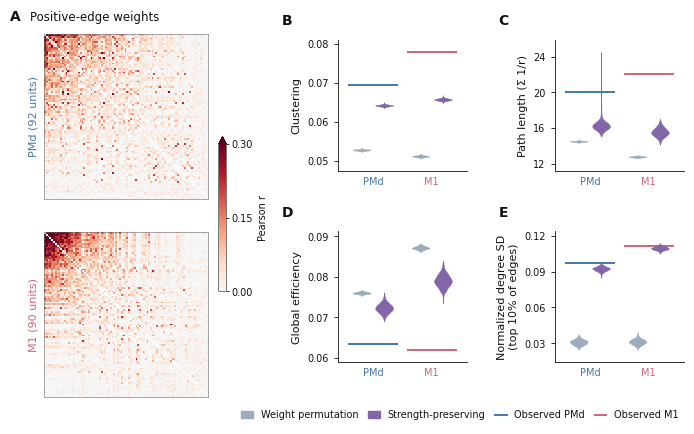

In [3]:
AREAS = ("PMd", "M1")
REFS = (("weight_permutation", REFERENCE, "Weight permutation"),
        ("strength_preserving", AUXILIARY, "Strength-preserving"))
METRICS_FIG2 = (
    ("clustering", "Clustering"),
    ("path_length", "Path length (Σ 1/r)"),
    ("efficiency", "Global efficiency"),
    ("degree_sd_10", "Normalized degree SD\n(top 10% of edges)"),
)

net = np.load(OUT / "networks.npz")
corr = np.array(net["full_correlation"], dtype=float)
np.fill_diagonal(corr, 0.0)
area_labels = np.asarray(net["area_labels"], dtype=int)

mats = {}
for code_idx, area in enumerate(AREAS):
    idx = np.flatnonzero(area_labels == code_idx)
    w = np.clip(corr[np.ix_(idx, idx)], 0.0, None)
    order = np.argsort(-w.sum(axis=1), kind="stable")
    mats[area] = w[np.ix_(order, order)]

emp = pd.read_csv(PART1 / "empirical_metrics.csv")
emp = emp[emp["weights"] == "positive"].set_index("area")
nulls = pd.read_csv(PART1 / "null_metrics.csv")
nulls = nulls[nulls["weights"] == "positive"]

allw = np.concatenate([m[np.triu_indices_from(m, 1)] for m in mats.values()])
vmax = np.ceil(np.percentile(allw[allw > 0], 99) * 20) / 20

fig = plt.figure(figsize=(DOUBLE, 4.3))
panel_label(fig, 0.012, 0.975, "A", "Positive-edge weights")

ims = []
for area, y in zip(AREAS, (0.535, 0.075)):
    ax = fig.add_axes([0.06, y, 0.235, 0.235 * DOUBLE / 4.3])
    shown = mats[area].copy()
    np.fill_diagonal(shown, np.nan)
    im = ax.imshow(np.ma.masked_invalid(shown), cmap=WEIGHT_CMAP, vmin=0, vmax=vmax,
                   interpolation="nearest", rasterized=True)
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_linewidth(0.4); sp.set_color(GRAY)
    ax.set_ylabel(f"{area} ({mats[area].shape[0]} units)", color=AREA_COLORS[area], labelpad=4)
    ims.append(im)

cax = fig.add_axes([0.310, 0.32, 0.011, 0.36])
cb = fig.colorbar(ims[0], cax=cax, extend="max", ticks=[0, vmax / 2, vmax])
cb.outline.set_linewidth(0.4)
cb.ax.tick_params(length=2, labelsize=7, pad=2)
cb.set_label("Pearson r", fontsize=7, labelpad=3)

xs, ys, w_ax, h_ax = (0.48, 0.79), (0.60, 0.155), 0.185, 0.305
for k, (metric, title) in enumerate(METRICS_FIG2):
    x, y = xs[k % 2], ys[k // 2]
    panel_label(fig, x - 0.08, y + h_ax + 0.06, "BCDE"[k])
    ax = fig.add_axes([x, y, w_ax, h_ax])
    for i, area in enumerate(AREAS):
        for (ref, color, _), dx in zip(REFS, (-0.19, 0.19)):
            vals = nulls.loc[(nulls["area"] == area) & (nulls["reference"] == ref), metric].to_numpy()
            parts = ax.violinplot(vals, positions=[i + dx], widths=0.30, showextrema=False, showmedians=False)
            for body in parts["bodies"]:
                body.set_facecolor(color); body.set_edgecolor(color)
                body.set_linewidth(0.4); body.set_alpha(1.0); body.set_zorder(5)
        obs = emp.loc[area, metric]
        ax.plot([i - 0.42, i + 0.42], [obs, obs], color=AREA_COLORS[area], lw=1.4, solid_capstyle="butt", zorder=3)
    ax.set_xlim(-0.6, 1.6); ax.set_xticks([0, 1], AREAS)
    for tick, area in zip(ax.get_xticklabels(), AREAS):
        tick.set_color(AREA_COLORS[area])
    ax.tick_params(axis="x", length=0, pad=4)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo - 0.06 * (hi - lo), hi + 0.06 * (hi - lo))
    ax.set_ylabel(title)

handles = [
    Patch(color=REFS[0][1], label=REFS[0][2]),
    Patch(color=REFS[1][1], label=REFS[1][2]),
    Line2D([], [], color=PMD, lw=1.4, label="Observed PMd"),
    Line2D([], [], color=M1, lw=1.4, label="Observed M1"),
]
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.655, 0.0), ncol=4,
           handlelength=1.2, columnspacing=1.0, fontsize=7)
save_fig(fig, "fig2_graph_metrics")

## Figure 3: Node-level distributions and PMd–M1 differences

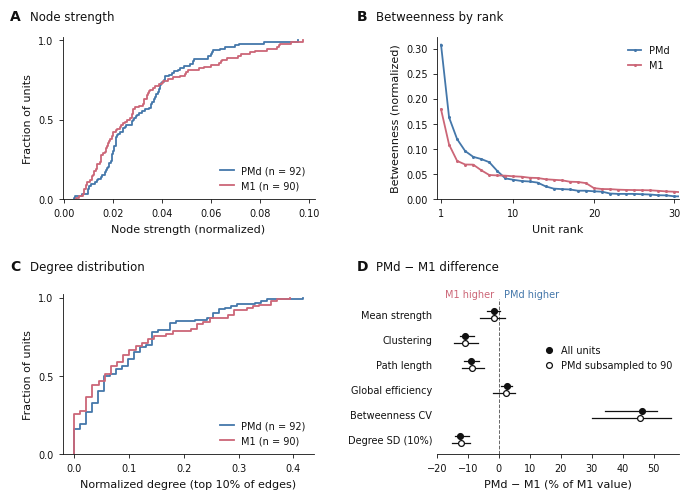

In [4]:
FOREST_METRICS = (
    ("mean_strength", "Mean strength"),
    ("clustering", "Clustering"),
    ("path_length", "Path length"),
    ("efficiency", "Global efficiency"),
    ("betweenness_cv", "Betweenness CV"),
    ("degree_sd_10", "Degree SD (10%)"),
)

nodes_df = pd.read_csv(PART1 / "node_metrics.csv")
diffs_df = pd.read_csv(PART1 / "area_differences.csv")

def ecdf(values):
    x = np.sort(np.asarray(values, dtype=float))
    return np.r_[x[0], x], np.r_[0.0, np.arange(1, x.size + 1) / x.size]

fig = plt.figure(figsize=(DOUBLE, 5.0))
ax_a = fig.add_axes([0.09, 0.605, 0.36, 0.325])
ax_b = fig.add_axes([0.625, 0.605, 0.345, 0.325])
ax_c = fig.add_axes([0.09, 0.095, 0.36, 0.32])
ax_d = fig.add_axes([0.625, 0.095, 0.345, 0.31])

for ax, col, xlab in ((ax_a, "strength", "Node strength (normalized)"),
                      (ax_c, "normalized_degree", "Normalized degree (top 10% of edges)")):
    for area in ("PMd", "M1"):
        x, y = ecdf(nodes_df.loc[nodes_df.area == area, col])
        n = int((nodes_df.area == area).sum())
        ax.step(x, y, where="post", color=AREA_COLORS[area], lw=1.3, label=f"{area} (n = {n})")
    ax.set_xlabel(xlab); ax.set_ylabel("Fraction of units")
    ax.set_ylim(0, 1.02); ax.set_yticks([0, 0.5, 1])
    ax.legend(loc="lower right", handlelength=1.4)

for area in ("PMd", "M1"):
    b = np.sort(nodes_df.loc[nodes_df.area == area, "betweenness"].to_numpy())[::-1]
    ax_b.plot(np.arange(1, b.size + 1), b, color=AREA_COLORS[area], lw=1.3, marker="o", ms=2.2, mew=0, label=area)
ax_b.set_xlabel("Unit rank"); ax_b.set_ylabel("Betweenness (normalized)")
ax_b.set_xlim(0.5, 30.5); ax_b.set_xticks([1, 10, 20, 30]); ax_b.set_ylim(bottom=0)
ax_b.legend(loc="upper right", handlelength=1.4)

ypos = np.arange(len(FOREST_METRICS))[::-1].astype(float)
for comparison, offset, mfc, label in (
    ("all_nodes", 0.15, INK, "All units"),
    ("size_matched", -0.15, "white", "PMd subsampled to 90"),
):
    sub = diffs_df[diffs_df.comparison == comparison].set_index("metric")
    for i, (metric, _) in enumerate(FOREST_METRICS):
        row = sub.loc[metric]
        scale = 100.0 / row.m1_observed
        ax_d.plot([row.percentile_ci025 * scale, row.percentile_ci975 * scale], [ypos[i] + offset] * 2, color=INK, lw=0.9)
        ax_d.plot(row.difference * scale, ypos[i] + offset, marker="o", ms=4.2, mec=INK, mew=0.9,
                  mfc=mfc, ls="none", label=label if i == 0 else None)
ax_d.axvline(0, color=GRAY, lw=0.7, ls="--", zorder=0)
ax_d.set_yticks(ypos, [lab for _, lab in FOREST_METRICS])
ax_d.tick_params(axis="y", length=0); ax_d.spines["left"].set_visible(False)
ax_d.set_ylim(ypos.min() - 0.6, ypos.max() + 0.6)
ax_d.set_xlim(-20, 58); ax_d.set_xticks([-20, -10, 0, 10, 20, 30, 40, 50])
ax_d.set_xlabel("PMd − M1 (% of M1 value)")
top = ypos.max() + 0.6
ax_d.text(-1.5, top, "M1 higher", color=M1, fontsize=7, ha="right", va="bottom")
ax_d.text(1.5, top, "PMd higher", color=PMD, fontsize=7, ha="left", va="bottom")
ax_d.legend(loc="center right", bbox_to_anchor=(1.0, 0.62), handlelength=1.0, borderaxespad=0.2)

panel_label(fig, 0.015, 0.985, "A", "Node strength")
panel_label(fig, 0.51, 0.985, "B", "Betweenness by rank")
panel_label(fig, 0.015, 0.485, "C", "Degree distribution")
panel_label(fig, 0.51, 0.485, "D", "PMd − M1 difference")
save_fig(fig, "fig3_node_area")

## Figure 4: Area modularity of the pooled and condition-specific networks

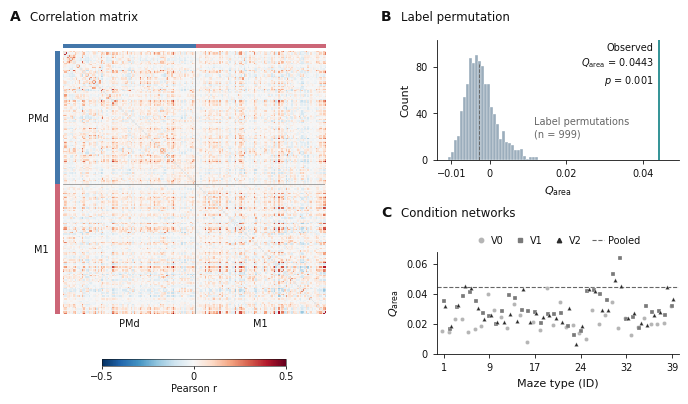

In [5]:
VERSION_STYLE = {0: ("#B5B5B5", "o"), 1: ("#7A7A7A", "s"), 2: ("#2B2B2B", "^")}

with np.load(OUT / "networks.npz") as z:
    corr = np.asarray(z["full_correlation"], dtype=float)
    labels = np.asarray(z["area_labels"], dtype=int)
with np.load(PART2 / "permutation_nulls.npz") as z:
    null = np.asarray(z["full"], dtype=float)
full_mod = json.loads((PART2 / "area_modularity.json").read_text())
cond = pd.read_csv(PART2 / "condition_summary.csv")
pooled_q = float(full_mod["q_observed"])

fig = plt.figure(figsize=(DOUBLE, 4.0))
panel_label(fig, 0.015, 0.975, "A", "Correlation matrix")
panel_label(fig, 0.545, 0.975, "B", "Label permutation")
panel_label(fig, 0.545, 0.485, "C", "Condition networks")

# A: Correlation matrix ordered by area
bounds_a = [0.090, 0.215, 0.375, 0.657]
ax = fig.add_axes(bounds_a)
order = np.argsort(labels, kind="stable")
groups = labels[order]
ordered = np.array(corr[np.ix_(order, order)], dtype=float, copy=True)
np.fill_diagonal(ordered, np.nan)
limit = max(0.1, min(1.0, np.ceil(np.nanmax(np.abs(ordered)) * 10) / 10))
im = ax.imshow(np.ma.masked_invalid(ordered), cmap=CORRELATION_CMAP, vmin=-limit, vmax=limit,
               interpolation="nearest", rasterized=True)
centers = [np.flatnonzero(groups == g).mean() for g in (0, 1)]
for b in np.flatnonzero(groups[:-1] != groups[1:]) + 0.5:
    ax.axhline(b, color="#808080", lw=0.5); ax.axvline(b, color="#808080", lw=0.5)
ax.set_xticks(centers, ["PMd", "M1"]); ax.set_yticks(centers, ["PMd", "M1"])
ax.tick_params(axis="x", length=0, pad=4); ax.tick_params(axis="y", length=0, pad=10)
for sp in ax.spines.values():
    sp.set_visible(False)
top = ax.inset_axes([0, 1.012, 1, 0.016])
top.imshow(groups[None, :], cmap=AREA_CMAP, vmin=0, vmax=1, aspect="auto", interpolation="nearest"); top.axis("off")
left_strip = ax.inset_axes([-0.028, 0, 0.016, 1])
left_strip.imshow(groups[:, None], cmap=AREA_CMAP, vmin=0, vmax=1, aspect="auto", interpolation="nearest"); left_strip.axis("off")
cax = fig.add_axes([bounds_a[0] + bounds_a[2] * 0.15, 0.085, bounds_a[2] * 0.70, 0.016])
cb = fig.colorbar(im, cax=cax, orientation="horizontal", ticks=[-limit, 0, limit])
cb.ax.set_xticklabels([f"{-limit:.1f}".replace("-", "−"), "0", f"{limit:.1f}"])
cb.outline.set_linewidth(0.4); cb.ax.tick_params(length=2, labelsize=7, pad=2)
cb.set_label("Pearson r", fontsize=7, labelpad=2)

# B: Label permutation histogram
ax_b = fig.add_axes([0.625, 0.600, 0.345, 0.300])
p_val = float(full_mod["p_upper"])
counts_h, _, _ = ax_b.hist(null, bins=30, color=REFERENCE, edgecolor="white", lw=0.25)
ax_b.axvline(np.median(null), color=GRAY, lw=0.7, ls="--", ymax=0.80)
ax_b.axvline(pooled_q, color=PRIMARY, lw=1.3)
ax_b.text(pooled_q - 0.0015, counts_h.max() * 1.12,
          f"Observed\n$Q_{{\\mathrm{{area}}}}$ = {pooled_q:.4f}\n$p$ = {p_val:.3f}",
          fontsize=7, ha="right", va="top", linespacing=1.35)
ax_b.text(np.percentile(null, 99.5) + 0.001, counts_h.max() * 0.30,
          f"Label permutations\n(n = {null.size})", fontsize=7, color=GRAY, ha="left", va="center", linespacing=1.3)
ax_b.set(xlim=(min(null.min(), pooled_q) - 0.003, max(null.max(), pooled_q) + 0.005),
         ylim=(0, counts_h.max() * 1.15), xlabel=r"$Q_{\mathrm{area}}$", ylabel="Count")
ax_b.set_xticks([-0.01, 0, 0.02, 0.04], ["−0.01", "0", "0.02", "0.04"])
ax_b.yaxis.set_major_locator(MaxNLocator(nbins=3, integer=True))

# C: 108 condition networks
ax_c = fig.add_axes([0.625, 0.115, 0.345, 0.255])
trial_types = np.sort(cond["trial_type"].unique())
positions = {v: i for i, v in enumerate(trial_types)}
handles = []
for version in sorted(cond["trial_version"].unique()):
    color, marker = VERSION_STYLE[int(version)]
    sub = cond[cond["trial_version"] == version].sort_values("trial_type")
    xs = sub["trial_type"].map(positions).to_numpy(float) + (version - 1) * 0.22
    ax_c.scatter(xs, sub["q_observed"], color=color, marker=marker, s=9, linewidths=0.2, edgecolors="white", zorder=3)
    handles.append(Line2D([], [], marker=marker, ls="none", color=color, markersize=3.2, label=f"V{int(version)}"))
ax_c.axhline(pooled_q, color=GRAY, lw=0.8, ls="--", zorder=1)
handles.append(Line2D([], [], color=GRAY, lw=0.8, ls="--", label="Pooled"))
high = max(float(cond["q_observed"].max()), pooled_q)
ax_c.set(xlim=(-1, len(trial_types)), ylim=(0, max(0.068, high * 1.07)),
         xlabel="Maze type (ID)", ylabel=r"$Q_{\mathrm{area}}$")
ticks = np.unique(np.linspace(0, len(trial_types) - 1, 6).round().astype(int))
ax_c.set_xticks(ticks, [str(trial_types[i]) for i in ticks])
ax_c.set_yticks([0, 0.02, 0.04, 0.06], ["0", "0.02", "0.04", "0.06"])
ax_c.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4,
            handlelength=1.2, columnspacing=1.1, handletextpad=0.4, borderaxespad=0.2)

save_fig(fig, "fig4_area_modularity")

## Figure 5: Louvain communities of the full pooled network

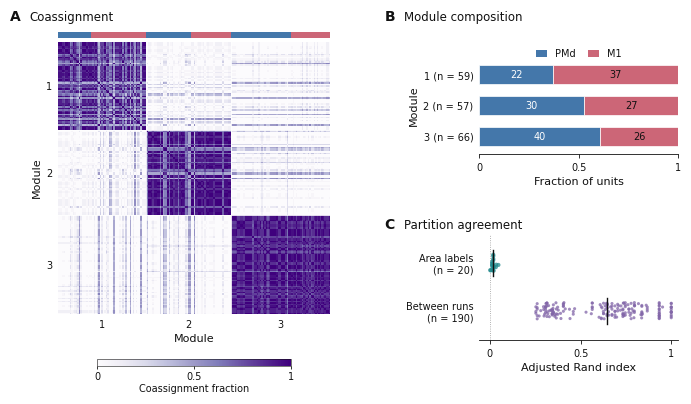

In [6]:
networks = np.load(OUT / "networks.npz")
partitions = np.load(PART2 / "community_partitions.npz")
runs = pd.read_csv(PART2 / "community_runs.csv")
labels = np.asarray(networks["area_labels"], dtype=int)
rep = np.asarray(partitions["representative_labels"], dtype=int)

fig = plt.figure(figsize=(DOUBLE, 4.0))
panel_label(fig, 0.020, 0.975, "A", "Coassignment")
panel_label(fig, 0.555, 0.975, "B", "Module composition")
panel_label(fig, 0.555, 0.455, "C", "Partition agreement")

# A: Coassignment matrix
bounds_a = [0.085, 0.215, 0.395, 0.680]
ax = fig.add_axes(bounds_a)
order = np.lexsort((labels, rep))
groups = rep[order]
ordered = np.asarray(partitions["coassignment"], dtype=float)[np.ix_(order, order)]
im = ax.imshow(ordered, cmap="Purples", vmin=0, vmax=1, interpolation="nearest", rasterized=True)
modules = np.unique(groups)
centers = [np.flatnonzero(groups == g).mean() for g in modules]
for b in np.flatnonzero(groups[:-1] != groups[1:]) + 0.5:
    ax.axhline(b, color="white", lw=0.6); ax.axvline(b, color="white", lw=0.6)
names = [str(m + 1) for m in modules]
ax.set_xticks(centers, names); ax.set_yticks(centers, names)
ax.tick_params(length=0, pad=4)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_xlabel("Module", labelpad=3); ax.set_ylabel("Module", labelpad=3)
top = ax.inset_axes([0, 1.012, 1, 0.022])
top.imshow(labels[order][None, :], cmap=AREA_CMAP, vmin=0, vmax=1, aspect="auto", interpolation="nearest"); top.axis("off")
cax = fig.add_axes([bounds_a[0] + bounds_a[2] * 0.15, 0.085, bounds_a[2] * 0.70, 0.016])
cb = fig.colorbar(im, cax=cax, orientation="horizontal", ticks=[0, 0.5, 1])
cb.ax.set_xticklabels(["0", "0.5", "1"])
cb.outline.set_linewidth(0.4); cb.ax.tick_params(length=2, labelsize=7, pad=2)
cb.set_label("Coassignment fraction", fontsize=7, labelpad=2)

# B: Module composition
ax_b = fig.add_axes([0.690, 0.615, 0.285, 0.240])
modules = np.unique(rep)
sizes = np.array([np.sum(rep == m) for m in modules])
pmd = np.array([np.sum((rep == m) & (labels == 0)) for m in modules])
m1 = sizes - pmd
for row, (n, a, b_cnt) in enumerate(zip(sizes, pmd, m1)):
    frac = a / n
    ax_b.barh(row, frac, color=PMD, height=0.6, edgecolor="white", linewidth=0.5)
    ax_b.barh(row, 1 - frac, left=frac, color=M1, height=0.6, edgecolor="white", linewidth=0.5)
    if a:
        ax_b.text(frac / 2, row, str(a), color="white", fontsize=7, ha="center", va="center")
    if b_cnt:
        ax_b.text((1 + frac) / 2, row, str(b_cnt), color=INK, fontsize=7, ha="center", va="center")
ax_b.set_yticks(range(len(modules)), [f"{m + 1} (n = {n})" for m, n in zip(modules, sizes)])
ax_b.set(xlim=(0, 1), ylim=(len(modules) - 0.45, -0.55))
ax_b.set_xticks([0, 0.5, 1], ["0", "0.5", "1"])
ax_b.set_xlabel("Fraction of units", labelpad=3); ax_b.set_ylabel("Module", labelpad=3)
ax_b.tick_params(axis="y", length=0, pad=4)
ax_b.spines[["left", "top", "right"]].set_visible(False)
ax_b.legend(handles=[Patch(facecolor=PMD, label="PMd"), Patch(facecolor=M1, label="M1")],
            loc="lower center", bbox_to_anchor=(0.5, 0.95), ncol=2,
            handlelength=1.1, columnspacing=1.3, fontsize=7, borderaxespad=0)

# C: Partition agreement (ARI)
ax_c = fig.add_axes([0.690, 0.150, 0.285, 0.265])
pairwise = np.asarray(partitions["pairwise_ari"])
between = pairwise[np.triu_indices(len(runs), k=1)]
with_area = runs["ari_area"].to_numpy(dtype=float)
rng_j = np.random.default_rng(20261026)
for row, (vals, col, sz) in enumerate([(with_area, PRIMARY, 9), (between, AUXILIARY, 5)]):
    ax_c.scatter(vals, row + rng_j.uniform(-0.17, 0.17, len(vals)), s=sz, color=col, alpha=0.75, edgecolors="none", zorder=2)
    med = float(np.median(vals))
    ax_c.plot([med, med], [row - 0.27, row + 0.27], color=INK, lw=1.0, zorder=3)
ax_c.set_yticks([0, 1], [f"Area labels\n(n = {len(with_area)})", f"Between runs\n(n = {len(between)})"])
ax_c.set(xlim=(-0.06, 1.04), ylim=(1.6, -0.6))
ax_c.set_xticks([0, 0.5, 1], ["0", "0.5", "1"])
ax_c.axvline(0, color="#999999", ls=":", lw=0.6, zorder=0)
ax_c.tick_params(axis="y", length=0, pad=4)
ax_c.set_xlabel("Adjusted Rand index", labelpad=3)
ax_c.spines[["left", "top", "right"]].set_visible(False)

save_fig(fig, "fig5_communities")

## Figure 6: Area modularity across task phases and over time

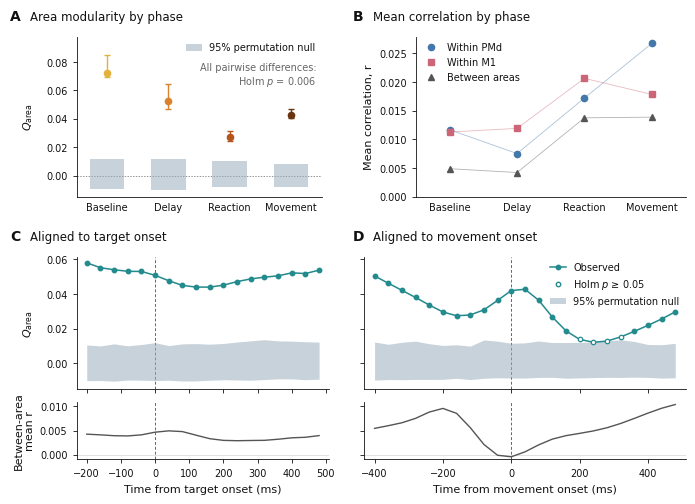

In [7]:
BETWEEN = "#555555"

ph = pd.read_csv(PART3 / "phase_summary.csv").set_index("phase").loc[list(PHASES)].reset_index()
pairs = pd.read_csv(PART3 / "phase_pair_tests.csv")
sw = pd.read_csv(PART3 / "sliding_windows.csv")
tgt = sw[sw["align"] == "target"].sort_values("window_center_ms")
mov = sw[sw["align"] == "movement"].sort_values("window_center_ms")

fig = plt.figure(figsize=(DOUBLE, 5.0))
left, right, gap = 0.105, 0.975, 0.05
axA = fig.add_axes([left, 0.61, 0.35, 0.32])
axB = fig.add_axes([0.59, 0.61, right - 0.59, 0.32])

pad = 30
span = {k: d.window_center_ms.max() - d.window_center_ms.min() + 2 * pad for k, d in (("C", tgt), ("D", mov))}
wC = (right - left - gap) * span["C"] / (span["C"] + span["D"])
wD = right - left - gap - wC
xD = left + wC + gap
axC = fig.add_axes([left, 0.225, wC, 0.265])
axD = fig.add_axes([xD, 0.225, wD, 0.265], sharey=axC)
axCr = fig.add_axes([left, 0.085, wC, 0.115], sharex=axC)
axDr = fig.add_axes([xD, 0.085, wD, 0.115], sharex=axD, sharey=axCr)

# A: Q_area per phase
x = np.arange(len(ph))
for i, row in ph.iterrows():
    axA.fill_between([i - 0.28, i + 0.28], row.null_q025, row.null_q975, color=REFERENCE, alpha=0.55, lw=0, zorder=1)
    c = PHASE_COLORS[row.phase]
    axA.errorbar(i, row.q_area, yerr=[[row.q_area - row.basic_ci025], [row.basic_ci975 - row.q_area]],
                 fmt="o", ms=4.5, color=c, mec=c, elinewidth=1.0, capsize=2.5, zorder=3)
axA.axhline(0, color=GRAY, lw=0.5, ls=(0, (2, 2)), zorder=0)
axA.set_xticks(x, [PHASE_LABELS[p] for p in ph.phase])
axA.set_xlim(-0.5, len(ph) - 0.5); axA.set_ylabel(r"$Q_{\mathrm{area}}$")
axA.tick_params(axis="x", length=0, pad=4)
axA.set_ylim(-0.015, ph.basic_ci975.max() * 1.15)
null_patch = Patch(color=REFERENCE, alpha=0.55, lw=0, label="95% permutation null")
axA.legend(handles=[null_patch], loc="upper right", handlelength=1.6, borderaxespad=0.2)
axA.text(0.98, 0.84, f"All pairwise differences:\nHolm $p$ = {pairs.p_holm.max():.3f}",
         transform=axA.transAxes, ha="right", va="top", fontsize=7, color=GRAY)

# B: Mean correlation per phase
for col, c, m, lab in (("mean_r_pmd", PMD, "o", "Within PMd"),
                       ("mean_r_m1", M1, "s", "Within M1"),
                       ("mean_r_between", BETWEEN, "^", "Between areas")):
    axB.plot(x, ph[col], color=c, lw=0.6, alpha=0.45, zorder=1)
    axB.plot(x, ph[col], color=c, marker=m, ms=4.5, lw=0, label=lab, zorder=2)
axB.set_xticks(x, [PHASE_LABELS[p] for p in ph.phase])
axB.set_xlim(-0.5, len(ph) - 0.5); axB.set_ylim(0, None); axB.set_ylabel("Mean correlation, r")
axB.tick_params(axis="x", length=0, pad=4)
axB.legend(loc="upper left", handlelength=1.8, borderaxespad=0.2)

# C, D: Sliding windows Q(t) and between-area r(t)
for ax, axr, d, lab in ((axC, axCr, tgt, "Time from target onset (ms)"),
                        (axD, axDr, mov, "Time from movement onset (ms)")):
    t = d.window_center_ms.to_numpy()
    ax.fill_between(t, d.null_q025, d.null_q975, color=REFERENCE, alpha=0.55, lw=0)
    ax.plot(t, d.q_area, color=PRIMARY, lw=1.1, zorder=2)
    sig = d.p_holm_all_windows.to_numpy() < 0.05
    ax.plot(t[sig], d.q_area.to_numpy()[sig], "o", ms=3.2, color=PRIMARY, zorder=3)
    ax.plot(t[~sig], d.q_area.to_numpy()[~sig], "o", ms=3.2, mfc="white", mec=PRIMARY, mew=0.9, zorder=3)
    ax.axvline(0, color=GRAY, lw=0.7, ls=(0, (3, 2)), zorder=0)
    axr.axhline(0, color=LIGHT, lw=0.6, zorder=0)
    axr.plot(t, d.mean_r_between, color=BETWEEN, lw=1.0)
    axr.axvline(0, color=GRAY, lw=0.7, ls=(0, (3, 2)), zorder=0)
    ax.tick_params(axis="x", labelbottom=False)
    axr.set_xlabel(lab)
    axr.set_xlim(t.min() - pad, t.max() + pad)

axC.set_ylabel(r"$Q_{\mathrm{area}}$"); axCr.set_ylabel("Between-area\nmean r")
axD.tick_params(axis="y", labelleft=False); axDr.tick_params(axis="y", labelleft=False)
axC.set_ylim(-0.015, None)
axCr.yaxis.set_major_locator(matplotlib.ticker.MultipleLocator(0.005))
for ax in (axA, axC, axCr):
    ax.yaxis.set_label_coords(0.046, 0.5, transform=blended_transform_factory(fig.transFigure, ax.transAxes))

axD.legend(handles=[
    Line2D([], [], color=PRIMARY, marker="o", ms=3.2, lw=1.1, label="Observed"),
    Line2D([], [], color=PRIMARY, marker="o", ms=3.2, mfc="white", lw=0, label="Holm $p$ ≥ 0.05"),
    null_patch,
], loc="upper right", handlelength=1.6, borderaxespad=0.2)

panel_label(fig, 0.01, 0.985, "A", "Area modularity by phase")
panel_label(fig, 0.50, 0.985, "B", "Mean correlation by phase")
panel_label(fig, 0.01, 0.545, "C", "Aligned to target onset")
panel_label(fig, 0.50, 0.545, "D", "Aligned to movement onset")
save_fig(fig, "fig6_phase_modularity")

## Figure 7: Louvain communities of the four task-phase networks

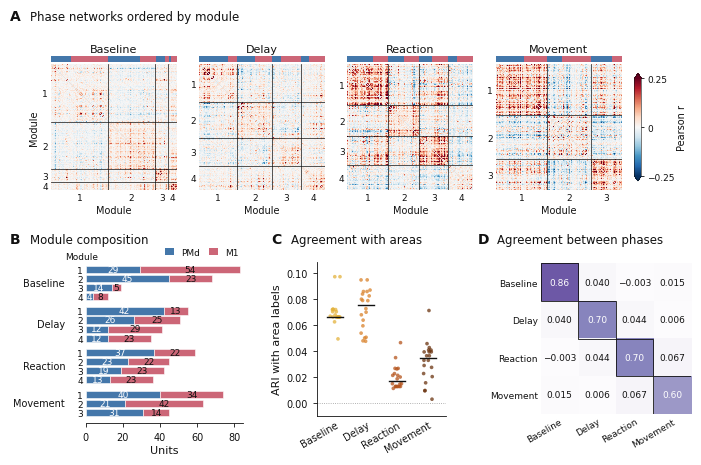

In [8]:
networks = np.load(PART3 / "phase_networks.npz")
partitions = np.load(PART3 / "community_partitions.npz")
corr_p = np.asarray(networks["correlations"], float)
areas_p = np.asarray(networks["area_labels"], int)
rep_p = np.asarray(partitions["representative"], int)
modules_df = pd.read_csv(PART3 / "community_modules.csv")
runs_p = pd.read_csv(PART3 / "community_runs.csv")
summary_p = pd.read_csv(PART3 / "community_summary.csv").set_index("phase")
phase_ari = pd.read_csv(PART3 / "community_phase_ari.csv", index_col=0).loc[list(PHASES), list(PHASES)].to_numpy(float)

off = ~np.eye(corr_p.shape[1], dtype=bool)
limit = np.ceil(np.percentile(np.abs(corr_p[:, off]), 99) / 0.05) * 0.05

H = 4.6
fig = plt.figure(figsize=(DOUBLE, H))

# A: Four phase matrices ordered by module
panel_label(fig, 0.012, 0.985, "A", "Phase networks ordered by module")
size, gap, x0, y0 = 0.180, 0.032, 0.070, 2.72 / H
height = size * DOUBLE / H
for k, phase in enumerate(PHASES):
    table = modules_df[modules_df["phase"] == phase].sort_values("module_rank")
    rank_map = np.empty(rep_p[k].max() + 1, dtype=int)
    rank_map[table["module_label"].to_numpy()] = table["module_rank"].to_numpy()
    ranks = rank_map[rep_p[k]]
    order = np.lexsort((areas_p, ranks))

    shown = corr_p[k][np.ix_(order, order)].copy()
    np.fill_diagonal(shown, np.nan)
    ax = fig.add_axes([x0 + k * (size + gap), y0, size, height])
    im = ax.imshow(np.ma.masked_invalid(shown), cmap=CORRELATION_CMAP, vmin=-limit, vmax=limit,
                   interpolation="nearest", rasterized=True)
    groups = ranks[order]
    for b in np.flatnonzero(groups[:-1] != groups[1:]) + 0.5:
        ax.axhline(b, color=INK, lw=0.5); ax.axvline(b, color=INK, lw=0.5)
    centers = [np.flatnonzero(groups == g).mean() for g in np.unique(groups)]
    names = [str(g + 1) for g in np.unique(groups)]
    ax.set_xticks(centers, names); ax.set_yticks(centers, names)
    ax.tick_params(length=0, pad=2, labelsize=6.5)
    for sp in ax.spines.values():
        sp.set_visible(False)
    top = ax.inset_axes([0, 1.02, 1, 0.045])
    top.imshow(areas_p[order][None, :], cmap=AREA_CMAP, vmin=0, vmax=1, aspect="auto", interpolation="nearest")
    top.axis("off")
    ax.set_title(PHASE_LABELS[phase], fontsize=8, pad=9, color=INK)
    ax.set_xlabel("Module", fontsize=7, labelpad=2)
    if k == 0:
        ax.set_ylabel("Module", fontsize=7, labelpad=2)

cax = fig.add_axes([x0 + 4 * size + 3 * gap + 0.018, y0 + 0.02, 0.010, height - 0.04])
cb = fig.colorbar(im, cax=cax, ticks=[-limit, 0, limit], extend="both")
cb.ax.set_yticklabels([f"{-limit:.2f}".replace("-", "−"), "0", f"{limit:.2f}"])
cb.outline.set_linewidth(0.4); cb.ax.tick_params(length=2, labelsize=6.5, pad=2)
cb.set_label("Pearson r", fontsize=7, labelpad=2)

# B: Module composition
panel_label(fig, 0.012, 2.30 / H, "B", "Module composition")
ax_b = fig.add_axes([0.120, 0.39 / H, 0.225, 1.62 / H])
row, yticks, ylabels, phase_mid = 0.0, [], [], []
for phase in PHASES:
    table = modules_df[modules_df["phase"] == phase].sort_values("module_rank")
    start = row
    for m in table.itertuples():
        ax_b.barh(row, m.n_pmd, color=PMD, height=0.78, edgecolor="white", lw=0.4)
        ax_b.barh(row, m.n_m1, left=m.n_pmd, color=M1, height=0.78, edgecolor="white", lw=0.4)
        ax_b.text(m.n_pmd / 2, row, str(m.n_pmd), color="white", fontsize=6.5, ha="center", va="center")
        ax_b.text(m.n_pmd + m.n_m1 / 2, row, str(m.n_m1), color=INK, fontsize=6.5, ha="center", va="center")
        yticks.append(row); ylabels.append(str(m.module_rank + 1))
        row += 1
    phase_mid.append(((start + row - 1) / 2, phase))
    row += 0.6
ax_b.set_yticks(yticks, ylabels); ax_b.tick_params(axis="y", length=0, pad=2, labelsize=6.5)
ax_b.text(-0.025, -0.9, "Module", transform=ax_b.get_yaxis_transform(), ha="center", va="bottom", fontsize=6.5)
for mid, phase in phase_mid:
    ax_b.text(-0.13, mid, PHASE_LABELS[phase], transform=ax_b.get_yaxis_transform(), ha="right", va="center", fontsize=7)
ax_b.set_ylim(row - 0.4, -0.9); ax_b.set_xlim(0, modules_df["n_units"].max() * 1.02)
ax_b.set_xlabel("Units", labelpad=2); ax_b.spines[["left", "top", "right"]].set_visible(False)
ax_b.legend(handles=[Patch(facecolor=PMD, label="PMd"), Patch(facecolor=M1, label="M1")],
            loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2, handlelength=1.0, columnspacing=1.0, fontsize=6.5, borderaxespad=0.1)

# C: ARI with area labels
panel_label(fig, 0.385, 2.30 / H, "C", "Agreement with areas")
ax_c = fig.add_axes([0.450, 0.466 / H, 0.185, 1.54 / H])
rng_c = np.random.default_rng(7)
for i, phase in enumerate(PHASES):
    vals = runs_p.loc[runs_p["phase"] == phase, "ari_area"].to_numpy(float)
    ax_c.scatter(i + rng_c.uniform(-0.16, 0.16, len(vals)), vals, s=7, color=PHASE_COLORS[phase], alpha=0.75, edgecolors="none", zorder=2)
    med = np.median(vals)
    ax_c.plot([i - 0.26, i + 0.26], [med, med], color=INK, lw=1.0, zorder=3)
ax_c.axhline(0, color="#999999", ls=":", lw=0.6, zorder=0)
ax_c.set_xticks(range(4), [PHASE_LABELS[p] for p in PHASES], rotation=30, ha="right", rotation_mode="anchor")
ax_c.tick_params(axis="x", length=0, pad=3); ax_c.set_xlim(-0.6, 3.6)
ax_c.set_ylim(min(0, runs_p["ari_area"].min()) - 0.01, runs_p["ari_area"].max() * 1.12)
ax_c.set_ylabel("ARI with area labels", labelpad=3)

# D: ARI between phases
panel_label(fig, 0.680, 2.30 / H, "D", "Agreement between phases")
ax_d = fig.add_axes([0.770, 0.466 / H, 0.215, 1.54 / H])
mat_d = phase_ari.copy()
np.fill_diagonal(mat_d, summary_p.loc[list(PHASES), "ari_between_runs_mean"].to_numpy(float))
cmap_d = ListedColormap(plt.get_cmap("Purples")(np.linspace(0.0, 0.85, 256)))
ax_d.imshow(mat_d, cmap=cmap_d, vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        v = mat_d[i, j]
        txt = f"{v:.2f}" if i == j else f"{v:.3f}"
        ax_d.text(j, i, txt.replace("-", "−"), ha="center", va="center", fontsize=6.5, color="white" if v > 0.5 else INK)
    ax_d.add_patch(Rectangle((i - 0.5, i - 0.5), 1, 1, fill=False, ec=INK, lw=0.6))
ax_d.set_xticks(range(4), [PHASE_LABELS[p] for p in PHASES], rotation=30, ha="right", rotation_mode="anchor")
ax_d.set_yticks(range(4), [PHASE_LABELS[p] for p in PHASES])
ax_d.tick_params(length=0, pad=2, labelsize=6.5)
for sp in ax_d.spines.values():
    sp.set_visible(False)

save_fig(fig, "fig7_phase_communities")